In [1]:
import numpy as np

In [2]:
import cv2

In [3]:
import matplotlib.pyplot as plt

In [4]:
import os

In [12]:
def homography_0to1(cam0, cam1):
    # cam0: higher or equal resolution
    # cam1: reference grid (lower resolution)

    sift = cv2.SIFT_create()

    # Detect keypoints and descriptors
    kp0, des0 = sift.detectAndCompute(cam0, None)
    kp1, des1 = sift.detectAndCompute(cam1, None)

    # Match descriptors
    bf = cv2.BFMatcher()
    matches = bf.knnMatch(des0, des1, k=2)

    # Lowe ratio test
    good = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good.append(m)

    if len(good) < 4:
        raise ValueError("Not enough matches to compute homography")

    # cam0 → cam1 point mapping
    src_pts = np.float32([kp0[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp1[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)

    # Homography: cam0 → cam1
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

    # Warp cam0 onto cam1 grid (NO upsampling)
    aligned_cam0 = cv2.warpPerspective(
        cam0,
        H,
        (cam1.shape[1], cam1.shape[0]),
        flags=cv2.INTER_AREA
    )

    return aligned_cam0, H, mask

In [23]:
loc = 'ground' # 'sky'
ts = '20260119_162018'

In [25]:
target_path = f'/gpfs01/euler/User/ydeng/Github/SCAM/pano/{ts}/cam0/{loc}_npys/'
os.chdir(target_path)

In [26]:
cropped_cam0s = [np.stack([np.load(f'./cam0_{ii}.npy'),np.load(f'./cam0_{ii}.npy'),np.load(f'./cam0_{ii}.npy')],axis=-1) for ii in range(12)]

In [27]:
sharpened_cam0 = []

for img in cropped_cam0s:
    img = img.astype(np.float32)

    blur = cv2.GaussianBlur(img, (0, 0), sigmaX=1.0)
    sharpened = img + 1.0 * (img - blur)

    sharpened = np.clip(sharpened, 0, 65535).astype(np.uint16)
    sharpened_cam0.append(sharpened)

In [28]:
loc = 'ground' # 'sky'
ts = '20260119_162018'
target_path = f'/gpfs01/euler/User/ydeng/Github/SCAM/pano/{ts}/cam1/{loc}_npys/'
os.chdir(target_path)

In [29]:
cropped_cam1s = [np.stack([np.load(f'./cam1_{ii}.npy'),np.load(f'./cam1_{ii}.npy'),np.load(f'./cam1_{ii}.npy')],axis=-1) for ii in range(12)]

In [30]:
img0s_8u = []
for img in sharpened_cam0:
    lo, hi = np.percentile(img, (0.5, 99.5))  # tune percentiles
    img8 = np.clip((img - lo) * 255.0 / (hi - lo), 0, 255).astype(np.uint8)
    img0s_8u.append(img8)

In [31]:
img1s_8u = []
for img in cropped_cam1s:
    lo, hi = np.percentile(img, (0.5, 99.5))  # tune percentiles
    img8 = np.clip((img - lo) * 255.0 / (hi - lo), 0, 255).astype(np.uint8)
    img1s_8u.append(img8)

In [32]:
cam0_aligned = []
for ii in range(len(img0s_8u)):
    aligned,_,_ = homography_0to1(img0s_8u[ii],img1s_8u[ii])
    cam0_aligned.append(aligned)

(np.float64(199.35247938074636), np.float64(67.1251595034478))

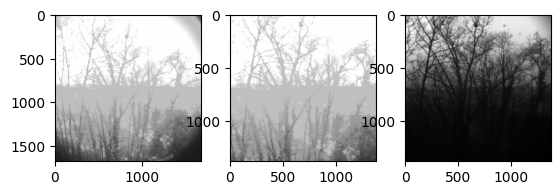

In [34]:
idx=3
plt.subplot(131)
plt.imshow(img0s_8u[idx])
plt.subplot(132)
plt.imshow(cam0_aligned[idx])
plt.subplot(133)
plt.imshow(img1s_8u[idx])
np.mean(cam0_aligned[idx]),np.mean(img1s_8u[idx])

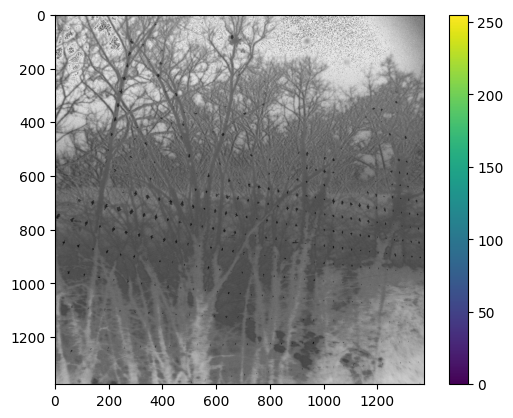

In [35]:
im = plt.imshow(img1s_8u[idx]-cam0_aligned[idx])
plt.colorbar(im)

In [36]:
overlaid = np.copy(img1s_8u)
for ii,img1 in enumerate(img1s_8u):
    # B G R 
    img1[:,:,1] = np.copy(cam0_aligned[ii][:,:,0])

In [37]:
np.sum(img1s_8u[0][:,:,0]==img1s_8u[0][:,:,1])/1676/1676

np.float64(0.00045034204635425865)

In [38]:
stitcher = cv2.Stitcher.create(cv2.Stitcher_PANORAMA)
status, panorama_mix = stitcher.stitch(img1s_8u)
if status == cv2.Stitcher_OK:
    cv2.imwrite(f"./cams_{loc}_pano.jpg", panorama_mix)
else:
    print("Can't stitch images, error code = %d" % status)